# 6. Data Aggregation
Problem Statement: Analyzing Sales Performance by Region in a Retail Company<br>
Dataset: "Retail_Sales_Data.csv"<br>
Description: The dataset contains information about sales transactions in a retail company. It
includes attributes such as transaction date, product category, quantity sold, and sales
amount. The goal is to perform data aggregation to analyze the sales performance by region
and identify the top-performing regions.<br>
Tasks to Perform:<br>
1. Import the "Retail_Sales_Data.csv" dataset.<br>
2. Explore the dataset to understand its structure and content.<br>
3. Identify the relevant variables for aggregating sales data, such as region, sales
amount, and product category.<br>
4. Group the sales data by region and calculate the total sales amount for each region.<br>
5. Create bar plots or pie charts to visualize the sales distribution by region.<br>
6. Identify the top-performing regions based on the highest sales amount.<br>
7. Group the sales data by region and product category to calculate the total sales
amount for each combination.<br>
8. Create stacked bar plots or grouped bar plots to compare the sales amounts across
different regions and product categories.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load dataset
df = pd.read_csv("Retail_Sales_Data.csv")

# Clean column names
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

In [3]:

# Explore dataset
print(df.head())
print(df.info())
print(df.describe())

   transaction_id  customer_id state  age shop_category  sales gender  \
0               1         1234    MP   10       Grocery     10      M   
1               2         1235    UP   21         Dairy     30      F   
2               3         1236    AP   23          Deli     23      F   
3               4         1237    RP   25          Meat     21      F   
4               5         1238    DP   27       Clothes     90      F   

   items_in_basket  
0                2  
1                3  
2                4  
3                4  
4                3  
<class 'pandas.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   transaction_id   312 non-null    int64
 1   customer_id      312 non-null    int64
 2   state            312 non-null    str  
 3   age              312 non-null    int64
 4   shop_category    312 non-null    str  
 5   sales            312 non-null

In [6]:
# Remove duplicate records
df = df.drop_duplicates()

In [7]:
# 1. Total sales by state
state_sales = df.groupby("state")["sales"].sum()

print("\nTotal Sales by State:")
print(state_sales)



Total Sales by State:
state
AP    12176
DP    23346
KP    10887
MP     4916
RP    11049
UP     4072
Name: sales, dtype: int64


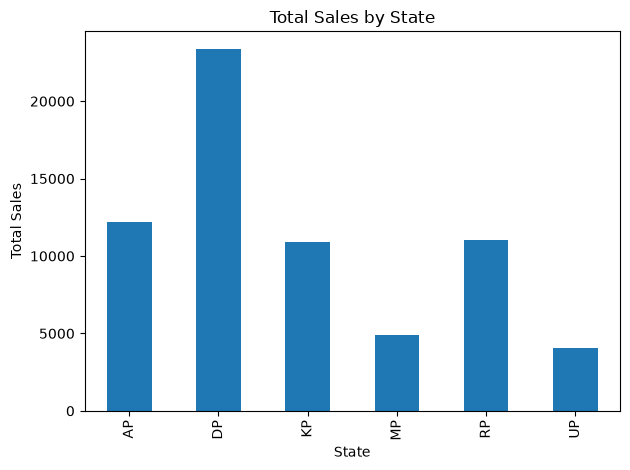

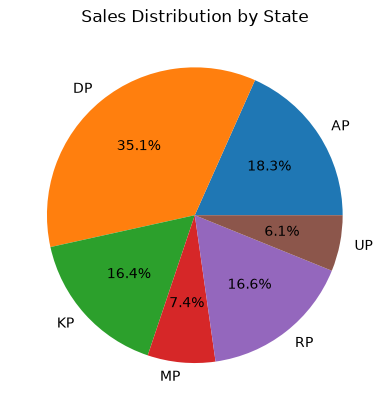


Top Performing State: DP
Highest Sales: 23346

Sales by State and Shop Category:
shop_category  Clothes  Dairy  Deli  Electronics  Grocery  Meat
state                                                          
AP                2127   1197  1303         3818      823  2908
DP                7133   6027  1723         4645     1736  2082
KP                3581    630  2595         2742       54  1285
MP                 711      0  1144          696      950  1415
RP                2167     74  1006         3087     2452  2263
UP                1077    816    87          500      729   863


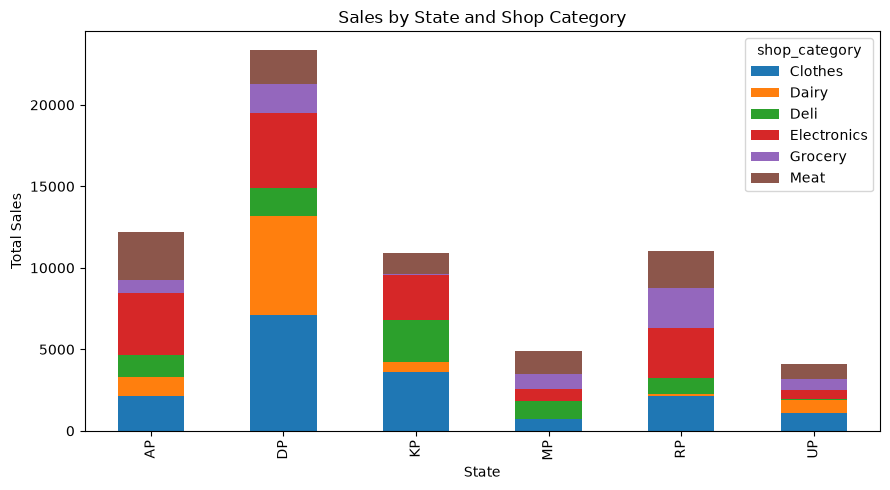

In [8]:
# 2. Bar chart
state_sales.plot(kind="bar", title="Total Sales by State")
plt.xlabel("State")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

# 3. Pie chart
state_sales.plot(kind="pie", autopct="%1.1f%%",
                 title="Sales Distribution by State")
plt.ylabel("")
plt.show()

# 4. Find top-performing state
print("\nTop Performing State:", state_sales.idxmax())
print("Highest Sales:", state_sales.max())

# 5. Sales by state and shop category
category_sales = df.pivot_table(
    index="state",
    columns="shop_category",
    values="sales",
    aggfunc="sum",
    fill_value=0
)

print("\nSales by State and Shop Category:")
print(category_sales)

# 6. Stacked bar chart
category_sales.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Sales by State and Shop Category")
plt.xlabel("State")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()